Measure the gap between the average head and the head in the wells for different pumping rates and different settings.

In [ ]:
from typing import List
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from tqdm import trange
import copy
import os
import json

import cvxpy as cp
import gurobipy as gp

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import IrrigationSchedulingModel, IrrigationSchedulingCostQuadraticDistance
from Components.Controllers import TimeVaryingCost_LQRc_RHG, LQRc_welfare
from Components.Solver import fbrs

In [2]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

In [3]:
myopic_folder = 'run_data/run_20250731-173601/'
game_folder = 'run_data/run_20250731-173816/'
welfare_folder = 'run_data/run_20250731-174208/'

# Construct Myopic data

In [4]:
parameter_file = "Components/Setup/model_parameters_myopic.json"
crop_repartition = np.array([[0.5, 0.8, 0.3], [0., 0.2, 0.3], [0.4, 0., 0.3], [0., 0., 0.4]])

In [ ]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")
cost_model = IrrigationSchedulingCostQuadraticDistance(parameter_file, model, crop_repartition)

In [6]:
cost_model.Rp_v = [elt * 0. for elt in cost_model.Rp_v]
cost_model.Rp_v_minus = [elt * 0. for elt in cost_model.Rp_v_minus]

state_input = [extr_cost * cost_model.input_v_to_state[v] for v, extr_cost
                        in enumerate(cost_model.extraction_cost)]
cost_model.Mp_v = [xu for xu in state_input]
cost_model.Lp_v = [-cost_model.top_head.T @ xu for xu in state_input]

In [7]:
# Initialize Controller
controller = TimeVaryingCost_LQRc_RHG(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    model.H_xu_x, model.H_xu_u, model.h_xu,
    solver='fbrs'
)

# Initialize receding horizon
receding_horizon = RecedingHorizon(system, model, controller, cost_model, parameter_file)
# Run loop
receding_horizon.run(time_period=365, display_results=True)
# Store type of control used
_, param_name = os.path.split(parameter_file)
with open(receding_horizon.result_folder + param_name, 'r+') as f:
    file_data = json.load(f)
    file_data["use_welfare"] = False
    file_data["crops_repartition"] = crop_repartition.tolist()
    f.seek(0)
    json.dump(file_data, f, indent=4)

/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/RecedingHorizon.py:145: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_h.show()
/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/RecedingHorizon.py:146: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_q.show()
/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/RecedingHorizon.py:147: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_p.show()


In [8]:
myopic_folder = receding_horizon.result_folder
myopic_folder

'run_data/run_20250806-113742/'

# Construct Game Data

In [ ]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")
cost_model = IrrigationSchedulingCostQuadraticDistance(parameter_file, model, crop_repartition)

In [10]:
# Initialize Controller
controller = TimeVaryingCost_LQRc_RHG(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    model.H_xu_x, model.H_xu_u, model.h_xu,
    solver='fbrs',
    overwrite_time_horizon=10
)

# Initialize receding horizon
receding_horizon = RecedingHorizon(system, model, controller, cost_model, parameter_file)
# Run loop
receding_horizon.run(time_period=365, display_results=True)
# Store type of control used
_, param_name = os.path.split(parameter_file)
with open(receding_horizon.result_folder + param_name, 'r+') as f:
    file_data = json.load(f)
    file_data["use_welfare"] = False
    file_data["crops_repartition"] = crop_repartition.tolist()
    f.seek(0)
    json.dump(file_data, f, indent=4)

In [11]:
game_folder = receding_horizon.result_folder
game_folder

'run_data/run_20250806-113847/'

# Construct Welfare Data

In [ ]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")
cost_model = IrrigationSchedulingCostQuadraticDistance(parameter_file, model, crop_repartition)

In [13]:
# Initialize Controller
controller = TimeVaryingCost_LQRc_RHG(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    model.H_xu_x, model.H_xu_u, model.h_xu,
    solver='fbrs',
    overwrite_time_horizon=10
)

# Initialize welfare controller
welfare_controller = LQRc_welfare(controller)
# Initialize receding horizon with welfare
receding_horizon = RecedingHorizon(system, model, welfare_controller, cost_model, parameter_file)
# Run loop
receding_horizon.run(time_period=365, display_results=True)
# Store type of control used
_, param_name = os.path.split(parameter_file)
with open(receding_horizon.result_folder + param_name, 'r+') as f:
    file_data = json.load(f)
    file_data["use_welfare"] = True
    file_data["crops_repartition"] = crop_repartition.tolist()
    f.seek(0)
    json.dump(file_data, f, indent=4)

In [14]:
welfare_folder = receding_horizon.result_folder
welfare_folder

'run_data/run_20250806-114229/'

# Display results

In [15]:
data_myopic = np.load(myopic_folder+'result_data.npz')
data_game = np.load(game_folder+'result_data.npz')
data_welfare = np.load(welfare_folder+'result_data.npz')

In [16]:
water_req = cost_model._get_water_requirement(0, 365)
rain = cost_model._get_available_water(0, 365)

n_well = int(sum(np.hstack(model.n_well_per_command)))
well_to_agent = np.zeros((model.n_agent, n_well))
indices = np.array(list(zip(model.well_to_agent.tolist(), range(n_well)))).T
well_to_agent[indices[0, :], indices[1, :]] = 1

player_pumping_m = well_to_agent @ data_myopic['q_rates']
player_pumping_g = well_to_agent @ data_game['q_rates']
player_pumping_w = well_to_agent @ data_welfare['q_rates']

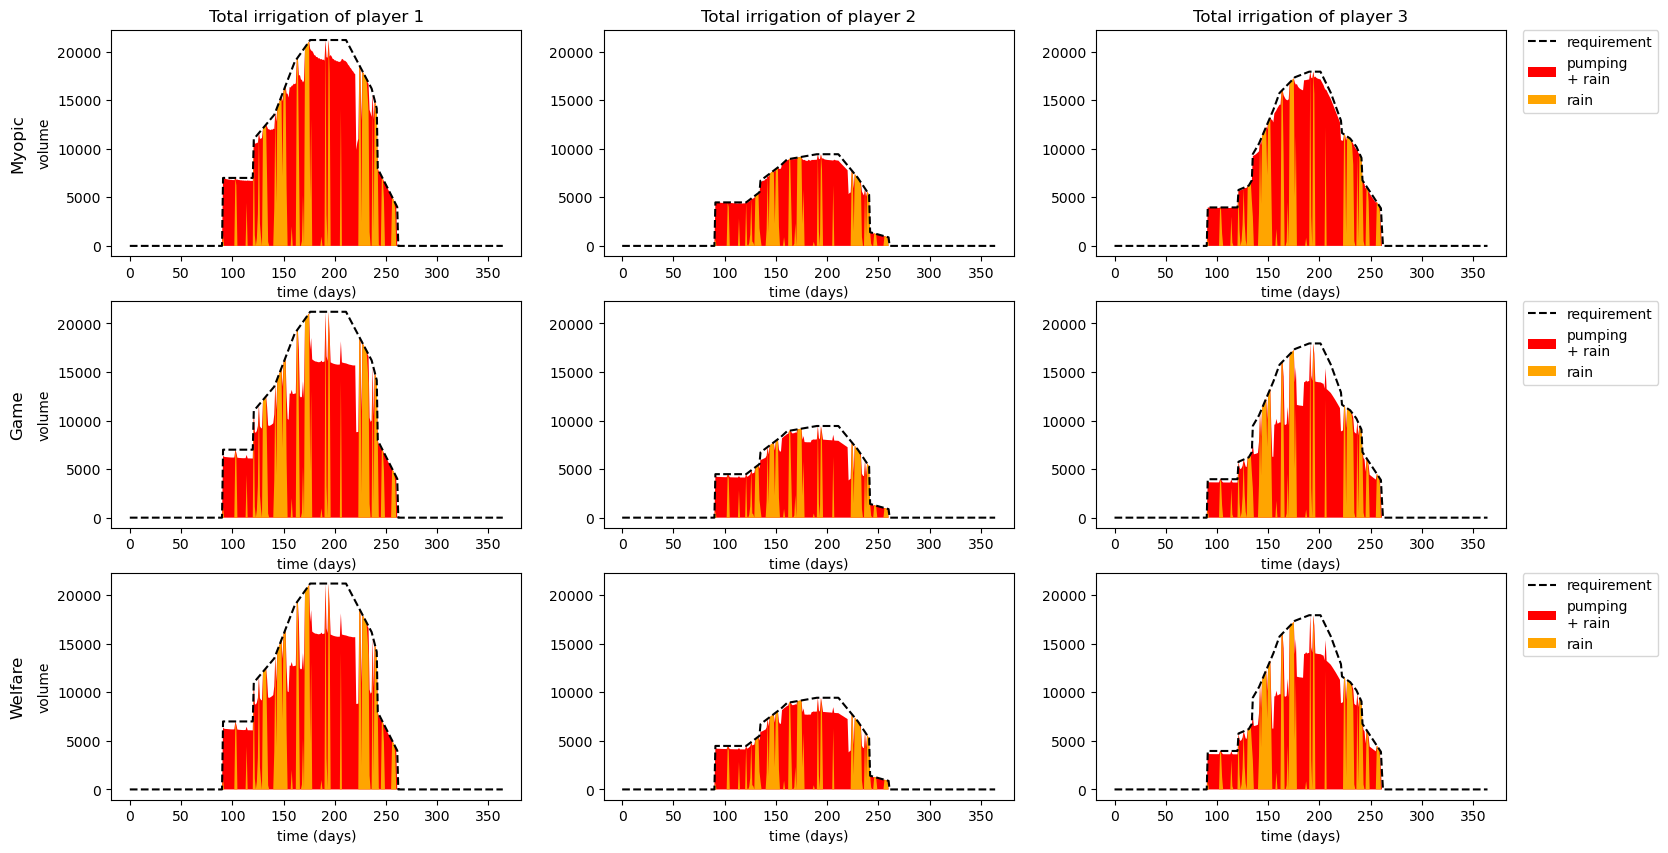

In [36]:
fig = plt.figure(figsize=(15+3,10))
ax = None
for ii in range(3):
    ax = fig.add_subplot(3, 3, ii+1, sharey=ax)
    ttl = f"Total irrigation of player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time (days)")
    if ii == 0:
        ax.set_ylabel("volume")
        ax.annotate('Myopic', xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - 5, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size='large', ha='right', va='center', rotation=90)
    ax.plot((water_req+rain)[ii, :, :].sum(axis=0), color="black", linestyle="--", label='requirement')
    #ax.fill((water_req+rain)[ii, :, :].sum(axis=0), label='requirement')
    ax.fill(-player_pumping_m[ii, :] + rain[ii,:,:].sum(axis=0), "r-", label='pumping\n+ rain')
    ax.fill(rain[ii,:,:].sum(axis=0), "orange", label='rain')
    # ax.plot((ET_min+rain)[ii, :, :].sum(axis=0), c="cyan", alpha=0.5, label=f'tolerance\n(cost increase: +{tol})')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)


for ii in range(3):
    ax = fig.add_subplot(3, 3, 3+ii+1, sharey=ax)
    ttl = f"Total irrigation of player {ii+1}"
    # ax.set_title(ttl)
    ax.set_xlabel("time (days)")
    if ii == 0:
        ax.set_ylabel("volume")
        ax.annotate('Game', xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - 5, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size='large', ha='right', va='center', rotation=90)
    ax.plot((water_req+rain)[ii, :, :].sum(axis=0), color="black", linestyle="--", label='requirement')
    #ax.fill((water_req+rain)[ii, :, :].sum(axis=0), label='requirement')
    ax.fill(-player_pumping_g[ii, :] + rain[ii,:,:].sum(axis=0), "r-", label='pumping\n+ rain')
    ax.fill(rain[ii,:,:].sum(axis=0), "orange", label='rain')
    # ax.plot((ET_min+rain)[ii, :, :].sum(axis=0), c="cyan", alpha=0.5, label=f'tolerance\n(cost increase: +{tol})')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

for ii in range(3):
    ax = fig.add_subplot(3, 3, 6+ii+1, sharey=ax)
    ttl = f"Total irrigation of player {ii+1}"
    # ax.set_title(ttl)
    ax.set_xlabel("time (days)")
    if ii == 0:
        ax.set_ylabel("volume")
        ax.annotate('Welfare', xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - 5, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size='large', ha='right', va='center', rotation=90)
    ax.plot((water_req+rain)[ii, :, :].sum(axis=0), color="black", linestyle="--", label='requirement')
    #ax.fill((water_req+rain)[ii, :, :].sum(axis=0), label='requirement')
    ax.fill(-player_pumping_w[ii, :] + rain[ii,:,:].sum(axis=0), "r-", label='pumping\n+ rain')
    ax.fill(rain[ii,:,:].sum(axis=0), "orange", label='rain')
    # ax.plot((ET_min+rain)[ii, :, :].sum(axis=0), c="cyan", alpha=0.5, label=f'tolerance\n(cost increase: +{tol})')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [18]:
(data_myopic['inputs'] - data_game['inputs']).max(), (data_myopic['inputs'] - data_game['inputs']).min()

(np.float64(5835.122752315492), np.float64(-7101.325882995467))

In [19]:
cost_myopic = np.hstack([- cost_model.compute_cost(data_myopic['corrected_h_wells'][:,[t+1]],
                                     model.reorganize_input_per_well(data_myopic['inputs'][:,[t]]),
                                     t) for t in range(364)])
cost_game = np.hstack([- cost_model.compute_cost(data_game['corrected_h_wells'][:,[t+1]],
                                     model.reorganize_input_per_well(data_game['inputs'][:,[t]]),
                                     t) for t in range(364)])
cost_welfare = np.hstack([- cost_model.compute_cost(data_welfare['corrected_h_wells'][:,[t+1]],
                                     model.reorganize_input_per_well(data_welfare['inputs'][:,[t]]),
                                     t) for t in range(364)])

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_16222/1774826815.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


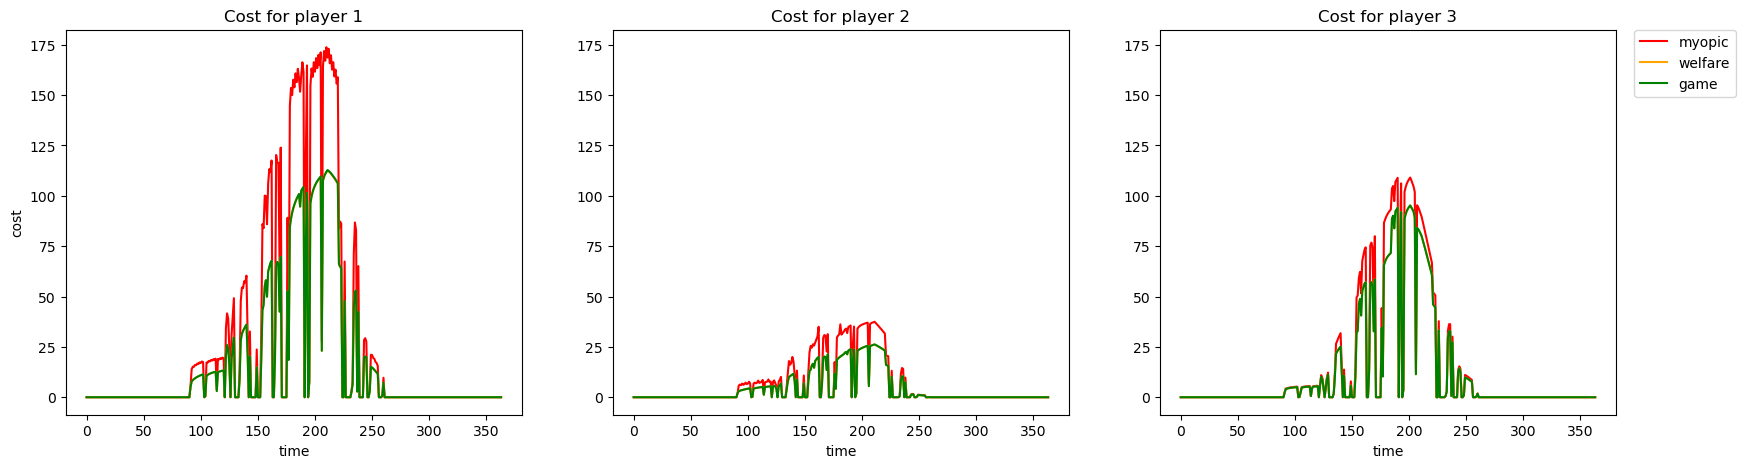

In [20]:
# Plot cost per player
fig = plt.figure(figsize=(15+5,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-cost_myopic[ii, :], 'red', label='myopic')
    ax.plot(-cost_welfare[ii, :], color="orange", label='welfare')
    ax.plot(-cost_game[ii, :], color="green", label='game')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

TODO: separate pumping vs irrigation cost + accumulated costs

## Separate costs

In [21]:
def compute_cost(x: np.ndarray, u: np.ndarray, time: int = None) -> np.ndarray:
    """parameter u of shape [n_well, n_crops] contains negative values"""
    u = u.reshape((np.hstack(cost_model.n_well_per_command).sum(dtype=int), cost_model.n_crops))
    ET = cost_model._get_water_requirement(time, 1)[:,:,0]
    Ry = cost_model._get_under_irrigation_weight(time, 1)
    pumping_cost = np.zeros((cost_model.n_agent, 1))
    under_irrigation_cost = np.zeros((cost_model.n_agent, 1))
    for v in range(cost_model.n_agent):
        input_indices = np.nonzero(cost_model.well_to_cell[:,cost_model.well_to_agent==v].T)[1]
        well_indices = np.arange(np.hstack(cost_model.n_well_per_command).sum(), dtype=int)[cost_model.well_to_agent==v]
        pumping_cost[v] = (-cost_model.extraction_cost[v] * (cost_model.top_head[input_indices] -\
            x[well_indices]).reshape(-1,1) * u[cost_model.well_to_agent==v,:].sum(axis=1).reshape(-1,1)).sum()
        under_irrigation = ET[v, :] + u[cost_model.well_to_agent==v,:].sum(axis=0)    # TODO: check dimensions
        under_irrigation_cost[v] = \
            under_irrigation.T @ sp.diags(Ry[v,:].flatten()) @ under_irrigation.T
    return pumping_cost, under_irrigation_cost

In [113]:
costs_myopic = np.hstack([- np.vstack(compute_cost(data_myopic['h_wells'][:,[t+1]],
                                     model.reorganize_input_per_well(data_myopic['inputs'][:,[t]]),
                                     t)) for t in range(364)])
costs_game = np.hstack([- np.vstack(compute_cost(data_game['h_wells'][:,[t+1]],
                                     model.reorganize_input_per_well(data_game['inputs'][:,[t]]),
                                     t)) for t in range(364)])
costs_welfare = np.hstack([- np.vstack(compute_cost(data_welfare['h_wells'][:,[t+1]],
                                     model.reorganize_input_per_well(data_welfare['inputs'][:,[t]]),
                                     t)) for t in range(364)])

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_16222/2906542977.py:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


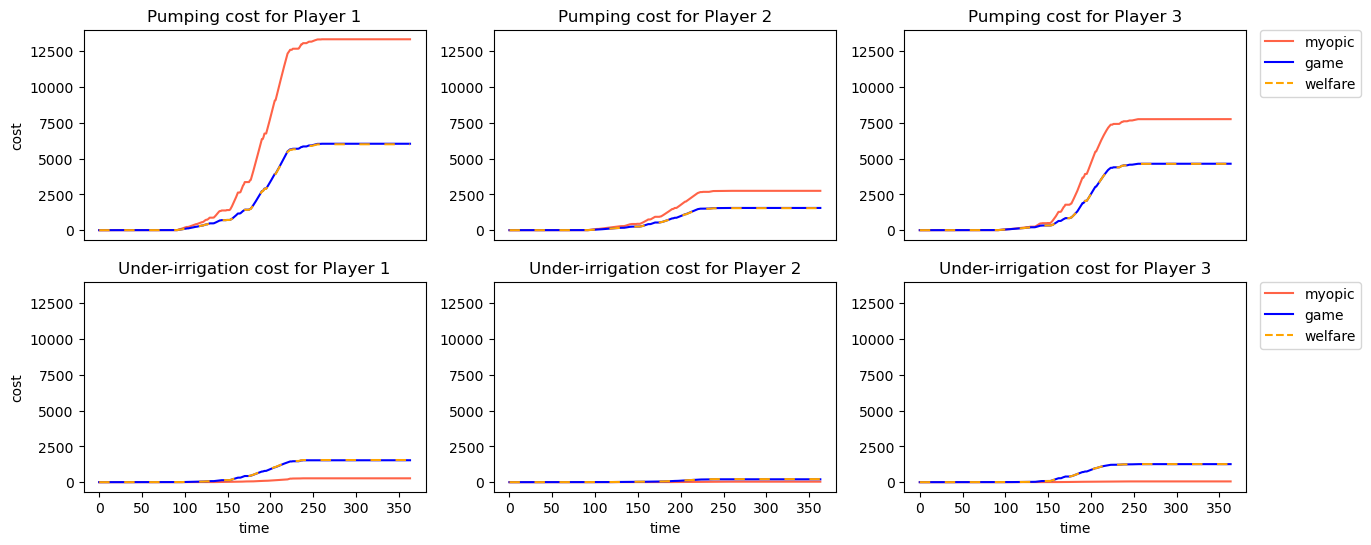

In [114]:
# Plot cost per player
fig = plt.figure(figsize=(15,6))
ax = None
for ii in range(3):
    ax = fig.add_subplot(2, 3, ii+1, sharey=ax)
    ttl = f"Pumping cost for Player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-np.cumsum(costs_myopic[ii, :]), 'tomato', label='myopic')
    ax.plot(-np.cumsum(costs_game[ii, :]), color="blue", label='game')
    ax.plot(-np.cumsum(costs_welfare[ii, :]), color="orange", linestyle=(0,(5,7)), label='welfare')
    ax.set_xticks([])
leg = ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
leg.get_lines()[-1].set_linestyle('--')

for ii in range(3):
    ax = fig.add_subplot(2, 3, 3+ii+1, sharey=ax)
    ttl = f"Under-irrigation cost for Player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-np.cumsum(costs_myopic[ii+3, :]), 'tomato', label='myopic')
    ax.plot(-np.cumsum(costs_game[ii+3, :]), color="blue", label='game')
    ax.plot(-np.cumsum(costs_welfare[ii+3, :]), color="orange", linestyle=(0,(5,7)), label='welfare')
leg = ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
leg.get_lines()[-1].set_linestyle('--')
fig.show()

In [136]:
costs_augmentation_welfare = np.where(abs(costs_game)<=1e-10, 0, ((costs_welfare-costs_game)/costs_game))
total_cost_augmentation_welfare = np.where(abs(((np.kron([[1,1]], np.eye(3)) @ costs_game)))<=1e-10, 0, ((np.kron([[1,1]], np.eye(3)) @ (costs_welfare))/((np.kron([[1,1]], np.eye(3)) @ costs_game))) - 1)
costs_augmentation_myopic = np.where(abs(costs_game)<=1e-10, 0, ((costs_myopic-costs_game)/costs_game))
total_cost_augmentation_myopic = np.where(abs(((np.kron([[1,1]], np.eye(3)) @ costs_game)))<=1e-10, 0, ((np.kron([[1,1]], np.eye(3)) @ (costs_myopic))/((np.kron([[1,1]], np.eye(3)) @ costs_game))) - 1)

cum_costs_augmentation_welfare = np.where(abs(np.cumsum(costs_game, axis=1))<=1e-10, 0, ((np.cumsum(costs_welfare, axis=1)-np.cumsum(costs_game, axis=1))/np.cumsum(costs_game, axis=1)))
cum_total_cost_augmentation_welfare = np.where(abs(((np.kron([[1,1]], np.eye(3)) @ np.cumsum(costs_game, axis=1))))<=1e-10, 0, ((np.kron([[1,1]], np.eye(3)) @ (np.cumsum(costs_welfare, axis=1)))/((np.kron([[1,1]], np.eye(3)) @ np.cumsum(costs_game, axis=1)))) - 1)
cum_costs_augmentation_myopic = np.where(abs(np.cumsum(costs_game, axis=1))<=1e-10, 0, ((np.cumsum(costs_myopic, axis=1)-np.cumsum(costs_game, axis=1))/np.cumsum(costs_game, axis=1)))
cum_total_cost_augmentation_myopic = np.where(abs(((np.kron([[1,1]], np.eye(3)) @ np.cumsum(costs_game, axis=1))))<=1e-10, 0, ((np.kron([[1,1]], np.eye(3)) @ (np.cumsum(costs_myopic, axis=1)))/((np.kron([[1,1]], np.eye(3)) @ np.cumsum(costs_game, axis=1)))) - 1)

In [133]:
np.cumsum(costs_game, axis=1).shape

(6, 364)

In [ ]:
total_cost_augmentation_myopic[0,:].argmax()

np.int64(154)

In [132]:
cost_game[0,154], costs_myopic[0,154]

(np.float64(-43.20266938709531), np.float64(-107.59060831651291))

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_16222/1010104507.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_16222/1010104507.py:47: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


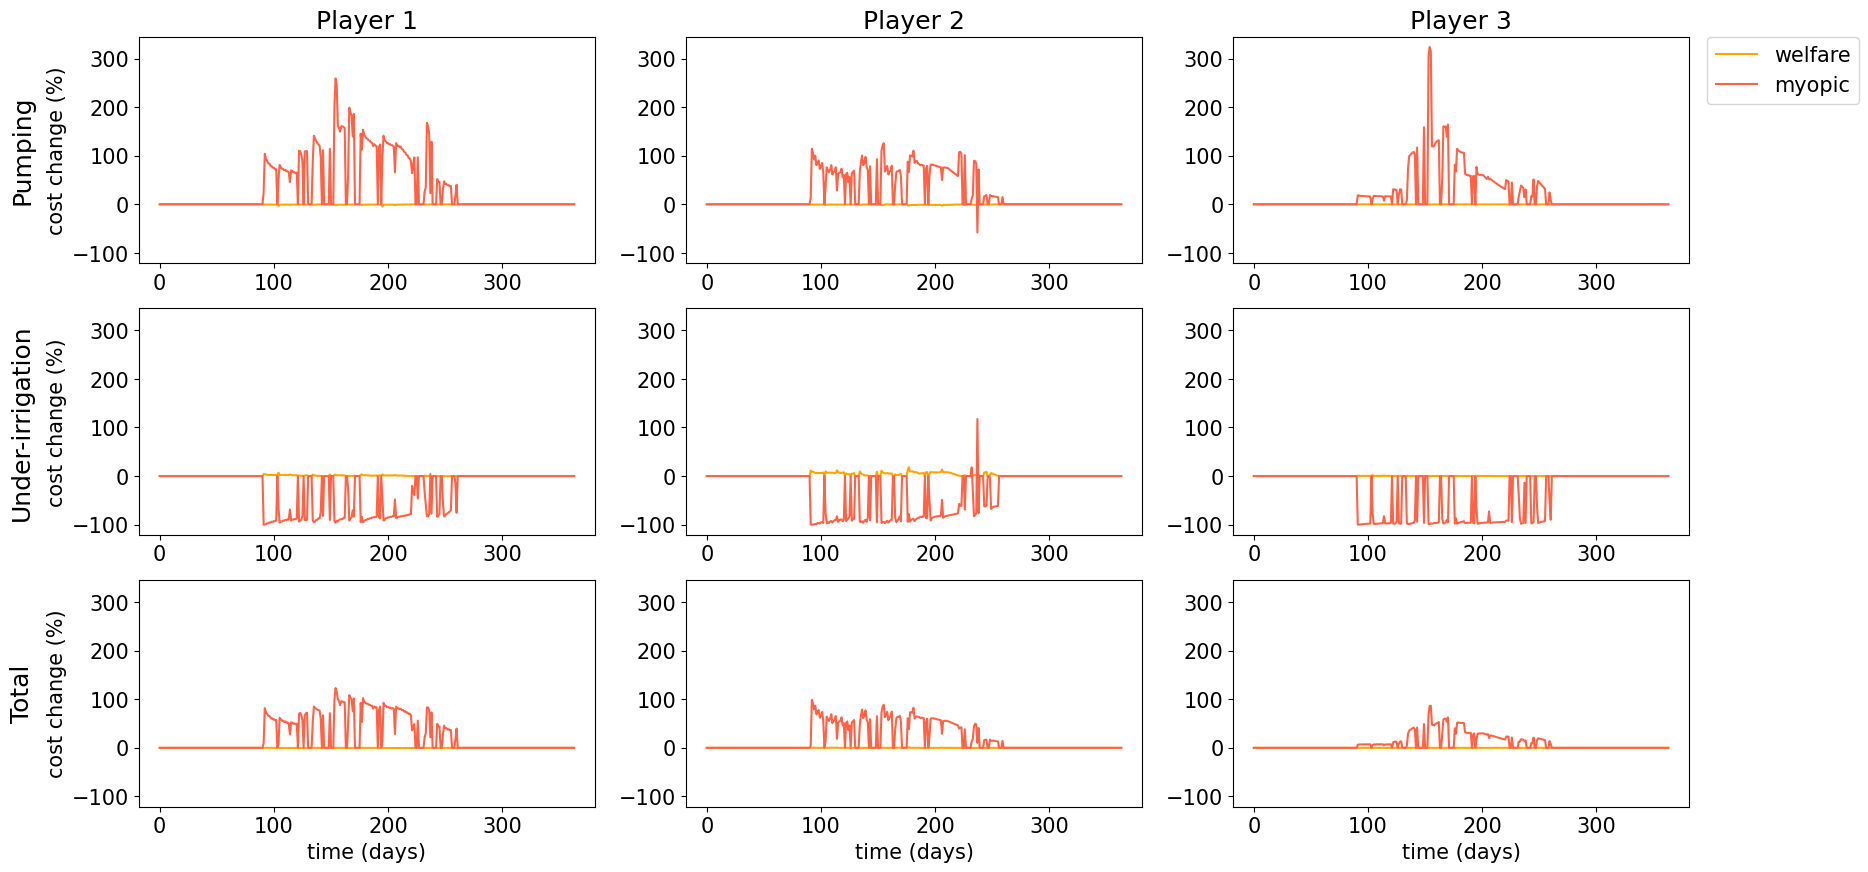

In [141]:
plt.rcParams.update({'font.size': 15})
# Plot cost per player
fig = plt.figure(figsize=(20,10))
ax = None
for ii in range(3):
    ax = fig.add_subplot(3, 3, ii+1, sharey=ax)
    ttl = f"Player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("cost change (%)")
        ax.annotate('Pumping', xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - 5, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size='large', ha='right', va='center', rotation=90)
    ax.plot(100*(costs_augmentation_welfare[ii, :]), color="orange", label='welfare')
    # ax.text(costs_augmentation_welfare.shape[1]-10, 100*costs_augmentation_welfare[ii,-1]+10, f"{int(costs_augmentation_welfare[ii,-1]*100):+}%")
    ax.plot(100*(costs_augmentation_myopic[ii, :]), color="tomato", label='myopic')
    # ax.text(costs_augmentation_myopic.shape[1]-10, 100*costs_augmentation_myopic[ii,-1]+10, f"{int(costs_augmentation_myopic[ii,-1]*100):+}%")
leg = ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

#ax=None
for ii in range(3):
    ax = fig.add_subplot(3, 3, 3+ii+1, sharey=ax)
    if ii == 0:
        ax.set_ylabel("cost change (%)")
        ax.annotate('Under-irrigation', xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - 5, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size='large', ha='right', va='center', rotation=90)
    ax.plot(100*(costs_augmentation_welfare[ii+3, :]), color="orange", label='welfare')
    # ax.text(costs_augmentation_welfare.shape[1]-10, 100*costs_augmentation_welfare[ii+3,-1]+10, f"{int(costs_augmentation_welfare[ii+3,-1]*100):+}%")
    ax.plot(100*(costs_augmentation_myopic[ii+3, :]), color="tomato", label='myopic')
    # ax.text(costs_augmentation_myopic.shape[1]-10, 100*costs_augmentation_myopic[ii+3,-1]+10, f"{int(costs_augmentation_myopic[ii+3,-1]*100):+}%")
fig.show()

#ax=None
for ii in range(3):
    ax = fig.add_subplot(3, 3, 6+ii+1, sharey=ax)
    ax.set_xlabel("time (days)")
    if ii == 0:
        ax.set_ylabel("cost change (%)")
        ax.annotate('Total', xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - 5, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size='large', ha='right', va='center', rotation=90)
    ax.plot(100*(total_cost_augmentation_welfare[ii, :]), color="orange", label='welfare')
    # ax.text(total_cost_augmentation_welfare.shape[1]-10, 100*total_cost_augmentation_welfare[ii,-1]+10, f"{int(total_cost_augmentation_welfare[ii,-1]*100):+}%")
    ax.plot(100*(total_cost_augmentation_myopic[ii, :]), color="tomato", label='myopic')
    # ax.text(total_cost_augmentation_myopic.shape[1]-10, 100*total_cost_augmentation_myopic[ii,-1]+10, f"{int(total_cost_augmentation_myopic[ii,-1]*100):+}%")
fig.show()

In [143]:
cum_costs_augmentation_myopic[:,-1]

array([ 1.20884477,  0.77026322,  0.67117187, -0.82401491, -0.82413924, -0.95787179])

In [73]:
from matplotlib.patches import Patch

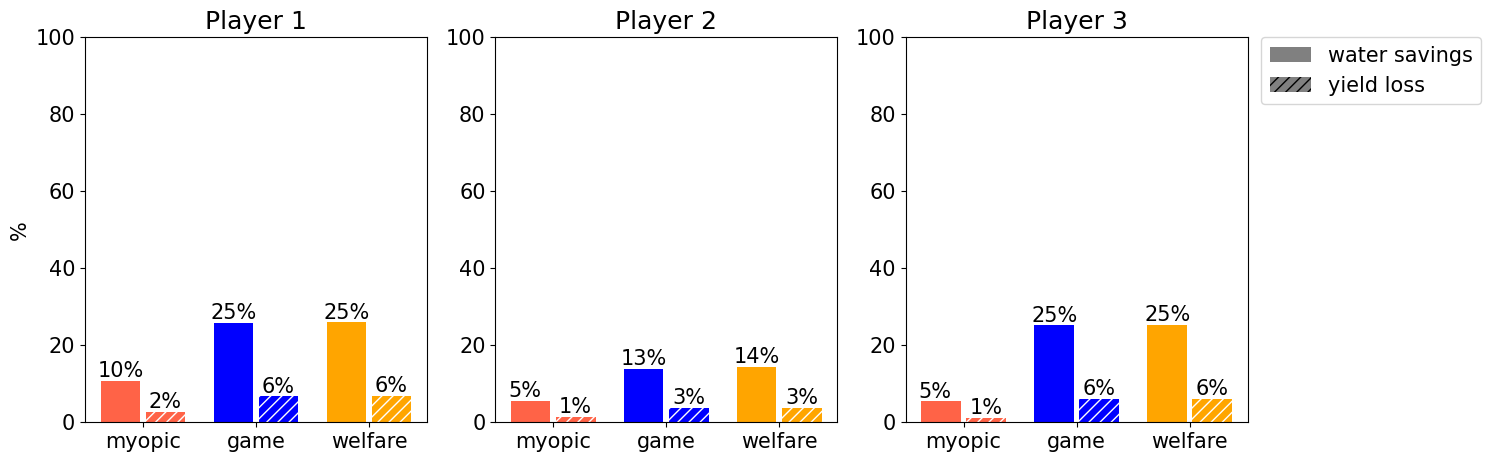

In [146]:
colors = ['tomato', 'blue', 'orange']
names = ['myopic', 'game', 'welfare']

water_spared = []
yield_loss = []
for d, (data, player_pumping) in enumerate(zip([data_myopic, data_game, data_welfare], [player_pumping_m, player_pumping_g, player_pumping_w])):
    crop_irrigation = -(sp.block_diag(cost_model.input_to_crop_irrigation_v) @ data['inputs']).reshape(3,4,-1)
    yield_proportion = np.where(water_req+rain==0, 0, (1-(crop_irrigation+rain)/(water_req+rain))*cost_model._get_yield_coefficient(0,365))

    std = np.array([np.std(yield_proportion[ii, jj, cost_model.Ky_stages[jj][1]:cost_model.Ky_stages[jj][-1]]) for ii in range(3) for jj in range(4)]).reshape(3,4)
    mean = np.array([np.mean(yield_proportion[ii, jj, cost_model.Ky_stages[jj][1]:cost_model.Ky_stages[jj][-1]]) for ii in range(3) for jj in range(4)]).reshape(3,4)

    water_spared.append((water_req.sum(axis=1).sum(axis=1) + player_pumping.sum(axis=1))/water_req.sum(axis=1).sum(axis=1))
    yield_loss.append((mean*(crop_repartition / crop_repartition.sum(axis=0)).T).sum(axis=1))
water_spared = np.vstack(water_spared)
yield_loss = np.vstack(yield_loss)


fig = plt.figure(figsize=(15,5))
ax = None 
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("%")
    for d in range(3):
        rects = ax.bar(np.linspace(0,2,3)[d], 100*water_spared[d,ii], width=0.35, color=colors[d], label='water savings')
        rects = ax.bar(np.linspace(0,2,3)[d]+0.40, 100*yield_loss[d,ii], width=0.35, color=colors[d], hatch='///', label='yield loss')
        for bar in rects:
            bar._hatch_color = (1.0, 1.0, 1.0, 1.0)
    ax.set_xticks(np.linspace(0,2,3)+0.2, names)
    for i, (w,y) in enumerate(zip(water_spared[:,ii], yield_loss[:,ii])):
        plt.text(i-0.2, 100*w+1, str(int(100*w))+'%')
        plt.text(i+0.25, 100*y+1, str(int(100*y))+'%')
    ax.set_ybound([0,100])
ax.legend(handles=[Patch(facecolor='grey', label='water savings'),
                   Patch(facecolor='grey', hatch='///', label='yield loss')],
          bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [97]:
((water_spared * water_req.sum(axis=1).sum(axis=1))-water_req.sum(axis=1).sum(axis=1)).sum(axis=1)

array([-3472227.24256652, -2896591.98373182, -2890958.26726027])

In [98]:
(((water_spared * water_req.sum(axis=1).sum(axis=1))-water_req.sum(axis=1).sum(axis=1)).sum(axis=1)-((water_spared * water_req.sum(axis=1).sum(axis=1))-water_req.sum(axis=1).sum(axis=1)).sum(axis=1)[1]) / ((water_spared * water_req.sum(axis=1).sum(axis=1))-water_req.sum(axis=1).sum(axis=1)).sum(axis=1)[1]

array([ 0.19872846, -0.        , -0.00194495])

20% more water for only a reduction of yield loss of 4 points in average.